<a href="https://colab.research.google.com/github/jamesaustin2564/IS-4487-F26/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 7: Data Transformation with Airbnb Listings

In this assignment, you will:
- Load the Airbnb dataset you cleaned in Assignment 6
- Apply data transformation techniques like scaling, binning, encoding, and feature creation
- Make the dataset easier to use for tasks like pricing analysis, guest segmentation, or listing recommendations
- Practice writing up your analysis clearly so a business audience — like a host, marketing manager, or city partner — could understand it

## Why This Matters

Airbnb analysts, hosts, and city partners rely on clean and well-structured data to make smart decisions. Whether they’re adjusting prices, identifying high-performing listings, or designing better guest experiences, they need data that’s transformed, organized, and ready for use.

This assignment helps you practice that kind of real-world thinking: taking messy real data and getting it ready for action.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

Choose a City & Upload Your Dataset
📥 Follow these steps:

Go to: https://insideairbnb.com/get-the-data/
Choose a city you’re interested in.
Download the file named: listings.csv.gz under that city.
In your notebook:
Open the left sidebar
Click the folder icon 📁
Click the upload icon ⬆️ and choose your listings.csv.gz file
Use the file path /content/listings.csv.gz when loading your data.
Import standard libraries (pandas, numpy, seaborn, matplotlib)

## 1. Setup and Load Your Data

You'll be working with the `cleaned_airbnb_data_6.csv` file you exported from Assignment 6. (Note: If you had significant errors with assignment 6, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)

### Do the following:
In Google Colab:
- Click the folder icon on the left sidebar
- Use the upload button to add your CSV file to the session
- Then use the code block below to read it into your notebook

Before getting started, make sure you import the libraries you'll need for this assignment:
- `pandas`, `numpy` for data manipulation
- `matplotlib.pyplot`, `seaborn` for visualizations


In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned data from Assignment 6
df = pd.read_csv('cleaned_airbnb_data_6.csv')
print(df.shape)
df.head()

(30259, 78)


,id,listing_url,scrape_id,last_scraped,source,name,description,picture_url,host_id,host_url,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2539,https://www.airbnb.com/rooms/2539,20260614073253,2026-06-15,city scrape,11 Min to Manhattan • Prospect Park • Fast WiFi,"Bright, serene room in a renovated apartment h...",https://a0.muscache.com/pictures/hosting/Hosti...,2787,https://www.airbnb.com/users/show/2787,...,4.89,5.00,4.78,4.78,NaN,5,0,5,0,0.08
1,6848,https://www.airbnb.com/rooms/6848,20260614073253,2026-06-14,city scrape,Only 2 stops to Manhattan studio,Comfortable studio apartment with super comfor...,https://a0.muscache.com/pictures/e4f031a7-f146...,15991,https://www.airbnb.com/users/show/15991,...,4.85,4.80,4.69,4.59,NaN,1,1,0,0,0.95
2,6872,https://www.airbnb.com/rooms/6872,20260614073253,2026-06-14,city scrape,Uptown Sanctuary w/ Private Bath (Month to Month),This charming distancing-friendly month-to-mon...,https://a0.muscache.com/pictures/miso/Hosting-...,16104,https://www.airbnb.com/users/show/16104,...,5.00,5.00,5.00,5.00,NaN,2,0,2,0,0.04
3,6990,https://www.airbnb.com/rooms/6990,20260614073253,2026-06-14,city scrape,UES Beautiful Blue Room,Beautiful peaceful healthy home,https://a0.muscache.com/pictures/45fb4ec7-6856...,16800,https://www.airbnb.com/users/show/16800,...,4.96,4.94,4.85,4.84,NaN,1,0,1,0,1.24
4,7097,https://www.airbnb.com/rooms/7097,20260614073253,2026-06-14,city scrape,"Perfect for Your Parents, With Garden & Patio",Parents/grandparents coming to town or are you...,https://a0.muscache.com/pictures/aaac19fc-4b4d...,17571,https://www.airbnb.com/users/show/17571,...,4.97,4.93,4.95,4.82,NaN,2,0,2,0,2.12


## 2. Check for Skew in a Numeric Column

### Business framing:  

Airbnb listings can have a wide range of values for things like price, availability, or reviews. These kinds of distributions can be hard to visualize, summarize, or model.

### Do the following:
Choose one **numeric column** that appears skewed and do the following:
- Plot a histogram
- Apply a transformation (e.g., log or other method)
- Plot again to compare

Skew before: 22.51
Skew after: 0.64


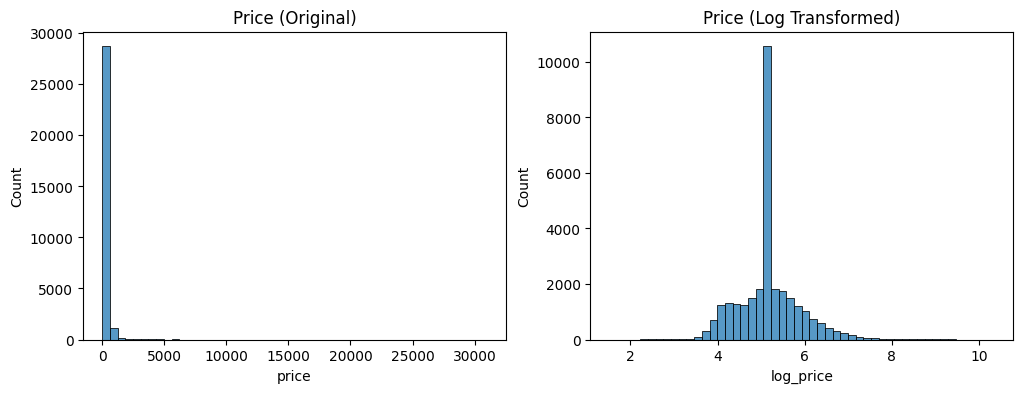

In [27]:
# Log transform price to reduce the long right tail
df['log_price'] = np.log(df['price'])

print("Skew before:", round(df['price'].skew(), 2))
print("Skew after:", round(df['log_price'].skew(), 2))

# Compare the original and transformed distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['price'], bins=50, ax=axes[0])
axes[0].set_title('Price (Original)')
sns.histplot(df['log_price'], bins=50, ax=axes[1])
axes[1].set_title('Price (Log Transformed)')
plt.show()

### Reflection:
1. What column did you examine?
2. What transformation did you try, and why?
3. How did the transformed version help make the data more usable for analysis or stakeholder review?

### ✍️ Your Response: 🔧
1. I examined the price column.

2. I applied a log transformation because price had a skew of 22.51. A few very high prices stretched the x-axis to about $30,000, so nearly every listing fell into a single bar.

3. The skew dropped to 0.64, and the log histogram shows a rough bell shape. A stakeholder can now see where most prices fall. The tall spike sits at the median log price of 5.16. It comes from the missing prices I filled with the median in Assignment 6.

## 3. Scale Two Numeric Columns

### Business framing:

If an analyst wanted to compare listing price to number of nights required, or create a model that weighs both, those values need to be on a similar scale.

### Do the following:
- Pick two numeric columns with different value ranges (e.g. one column may have a min of 0 and a max of 255; another column may have a min of 100 and a max of 400)
- Use Min-Max scaling on one column (the range should be “shrinked” down to just 0-1)
- Use Z-score Normalization (aka standardization) on the other column.
- Add 2 new columns to the dataset. These 2 new columns should be the ones you just created.

In [28]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Min-Max scale
df['availability_365_minmax'] = MinMaxScaler().fit_transform(df[['availability_365']])

# Z-score scale
df['log_price_zscore'] = StandardScaler().fit_transform(df[['log_price']])

print(df[['availability_365', 'availability_365_minmax', 'log_price', 'log_price_zscore']].describe().round(2))

       availability_365  availability_365_minmax  log_price  log_price_zscore
count          30259.00                 30259.00   30259.00          30259.00
mean             185.84                     0.51       5.19             -0.00
std              139.36                     0.38       0.71              1.00
min                0.00                     0.00       1.52             -5.15
25%               27.00                     0.07       4.85             -0.47
50%              207.00                     0.57       5.16             -0.03
75%              318.00                     0.87       5.47              0.40
max              365.00                     1.00      10.34              7.25



### Reflection:
1. What two columns did you scale, and which methods did you use?
2. When might these scaled values be more useful than the originals?
3. Who at Airbnb might benefit from this transformation and why?

### ✍️ Your Response: 🔧
1. I used Min-Max scaling on availability_365 and Z-score standardization on log_price. Availability ranges from 0 to 365 days, while log price ranges from 1.52 to 10.34. I standardized log price instead of raw price because the raw column is too skewed for a z-score to mean much.

2. Scaled values are more useful when a model weighs both columns together, such as a regression or a distance-based model. If the columns are not scaled, the one with larger numbers can dominate the result.

3. A pricing analyst would benefit. A model could weigh availability and price together without the larger numbers taking over. The z-score also flags extreme prices right away, since the highest log price sits 7.25 standard deviations above the mean.

## 4. Group a Numeric Column into Categories

### Business framing:  

Let’s say an Airbnb marketing team wants to segment listings by review activity. They don’t want exact numbers — they just want to know if a listing has “low,” “medium,” or “high” review volume.

### Do the following:

- Choose a numeric column that could be grouped (e.g., reviews, availability).
- You’ll want to group the values of this column into 3 or 4 bins
- Create a new column. The values of this column will be the labels: “Low”, “Medium”, and “High.” These labels should correspond to your bins.

In [29]:
# Group listings by review volume
df['review_volume'] = pd.cut(df['number_of_reviews'], bins=[0, 5, 50, np.inf], labels=['Low', 'Medium', 'High'], include_lowest=True)

print(df['review_volume'].value_counts())

review_volume
Low       15918
Medium     8907
High       5434
Name: count, dtype: int64


### Reflection:
1. What column did you group, and how many categories did you use?
2. Why might someone prefer this grouped view over raw numbers?
3. Who would this help at Airbnb, and how?

### ✍️ Your Response: 🔧
1. I grouped number_of_reviews into three categories: Low (0 to 5 reviews), Medium (6 to 50), and High (more than 50).

2. Raw review counts are hard to compare at a glance. Three labels make the split clear: 15,918 listings are Low, 8,907 are Medium, and 5,434 are High.

3. The marketing team could target the 15,918 Low listings with promotions that help hosts earn more reviews. They could also feature the 5,434 High listings, since each one has been reviewed by more than 50 guests.

## 5. Create Two New Business-Relevant Variables

### Business framing:  

Stakeholders often want to know things like: What’s the cost per night? Are listings geared toward long-term stays? These kinds of features aren’t always in the dataset — analysts create them.

### Do the following:

- Think of two new columns you can create using the data you already have.
  - One might be a ratio or interaction between columns (e.g., price ÷ nights).
  - The other might be a flag based on a condition (e.g., stays longer than 30 days).
- Add the new columns to your DataFrame.

In [30]:
# Price per guest the listing can hold
df['price_per_guest'] = df['price'] / df['accommodates']

# Flag listings that require stays of 30 nights or more
df['long_term_stay'] = (df['minimum_nights'] >= 30).astype(int)

print(df[['price', 'accommodates', 'price_per_guest', 'minimum_nights', 'long_term_stay']].head())
print(df['price_per_guest'].describe().round(2))
print(df['long_term_stay'].value_counts())

    price  accommodates  price_per_guest  minimum_nights  long_term_stay
0  113.97             2           56.985            30.0               1
1  117.27             3           39.090            30.0               1
2   80.06             1           80.060            30.0               1
3   77.17             1           77.170            30.0               1
4  202.47             2          101.235            30.0               1
count    30259.00
mean        95.26
std        148.61
min          2.29
25%         46.00
50%         78.75
75%        101.50
max      10944.83
Name: price_per_guest, dtype: float64
long_term_stay
1    24717
0     5542
Name: count, dtype: int64


### Reflection:
1. What two new columns did you create and why?
2. Who would use them (e.g., host, manager, or platform)?
3. How could they help someone make a better decision?

### ✍️ Your Response: 🔧
1. I created price_per_guest, which divides price by the number of guests a listing can hold, and long_term_stay, which flags listings that require 30 or more nights. Price alone does not show value for a group, and the minimum stay decides who can book.

2. Guests and hosts would use price_per_guest to compare listings of different sizes. The platform and city partners would use long_term_stay to track how many listings require stays of 30 nights or more.

3. The flag shows that 24,717 of 30,259 listings require stays of 30 nights or more. A manager who plans a short-stay promotion would learn that only 5,542 listings qualify. A host could also check whether their price per guest sits near the median of $78.75.



## 6. Encode a Categorical Column

### Business framing:  

Let’s say you’re helping the Airbnb data science team build a model to predict booking rates. Categorical columns like `room_type`, `neighbourhood`, or `cancellation_policy` can’t be used in models unless they’re converted to numbers.

### Do the following:
- Choose one categorical column from your dataset (e.g., room type or neighborhood group)
- Decide on an encoding method:
  - Use one-hot encoding for nominal (unordered) categories
  - Use ordinal encoding (a ranking) only if the categories have a clear order
- Apply the encoding using `pandas` or another tool
- Add the new encoded column(s) to your DataFrame

In [31]:
# One-hot encode room type
df = pd.get_dummies(df, columns=['room_type'], prefix='room', dtype=int)

print(df.filter(like='room_').sum())

room_Entire home/apt    16808
room_Hotel room           520
room_Private room       12713
room_Shared room          218
dtype: int64


### Reflection:
1. What column did you encode and why?
2. What encoding method did you use?
3. How could this transformation help a pricing model, dashboard, or business report?

### ✍️ Your Response: 🔧
1. I encoded room_type. Room type shapes what a guest gets for the price, and a model cannot read text labels.
2. I used one-hot encoding because the four room types have no natural order. It created four 0/1 columns, with 16,808 entire homes, 12,713 private rooms, 520 hotel rooms, and 218 shared rooms.
3. A pricing model can now estimate how much each room type adds to or takes away from price. A dashboard could also sum each column to show the mix of listings in a neighborhood.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 11**, where you'll use the data in a regression model.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_7.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```

In [32]:
# Drop text, URL, and scrape columns that a model cannot use
drop_cols = ['listing_url', 'scrape_id', 'last_scraped', 'source', 'name', 'description',
             'picture_url', 'host_url', 'host_profile_id', 'host_profile_url', 'host_name',
             'host_location', 'host_about', 'host_picture_url', 'amenities', 'bathrooms_text',
             'price_quote_checkin_date', 'price_quote_checkout_date', 'price_quote_raw',
             'calendar_last_scraped', 'license']
df = df.drop(columns=drop_cols)

# Convert t/f columns to 1/0
tf_cols = ['host_is_superhost', 'host_has_profile_pic', 'host_identity_verified', 'has_availability']
for col in tf_cols:
    df[col] = df[col].map({'t': 1, 'f': 0})

df.to_csv('cleaned_airbnb_data_7.csv', index=False)
print(df.shape)

(30259, 66)


## 8. Reflection

You’ve applied the same kinds of transformation techniques used in real Airbnb analytics projects — from pricing engines to host tools to tourism dashboards.

Now step back and reflect.

### Reflection:
1. What transformation step felt most important or interesting?
2. Which of your changes would be most useful to a host, analyst, or city planner?
3. If you were going to build a tool or dashboard, what would you do next with this data?
4. How does this relate to your customized learning outcome you created in canvas?



### ✍️ Your Response: 🔧

1. The log transformation of price was the most interesting step. The skew fell from 22.51 to 0.64, and the new histogram also exposed the spike from my median fill in Assignment 6. The transformation made the data easier to read and showed the cost of an earlier cleaning choice.

2. The long_term_stay flag would be most useful to a city planner. It shows that 24,717 of 30,259 listings require stays of 30 nights or more, so most listings in this dataset do not serve short visits. A planner could track that share over time to see how the market changes.

3. I would build a map dashboard that colors listings by price per guest and filters by borough, room type, and review volume. Before the regression in Assignment 11, I would also recover missing bedroom and bathroom counts and decide how to treat the median-filled prices.

4. My learning outcome is to build a Python workflow that cleans and consistently categorizes messy client transaction data, so a diligence team can flag non-recurring items and quality-of-earnings adjustments without re-sorting by hand. Assignment 6 practiced the cleaning half, and this assignment practiced the categorizing half. The review volume bins and the long-term stay flag work like the rules an analyst would use to sort transactions and flag items for review.



## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [34]:
!jupyter nbconvert --to html "assignment_07_data_transformation.ipynb"

[NbConvertApp] Converting notebook assignment_07_data_transformation.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 375241 bytes to assignment_07_data_transformation.html
